# **PROJET DE CLASSIFICATION BINAIRE DE PATIENTS**
## Master IAOC - Université Ibn Tofail
## Module : Techniques d'Intelligence Artificielle

**- Dataset :** Multi-Class Chronic Disease Data Warehouse.

**- Objectif :** Développer un modèle de classification binaire permettant de prédire si un patient est « Normal » ou « Abnormal » (c’est-à-dire souffrant d’au moins une maladie chronique parmi le diabète, l’hypertension ou une maladie cardiaque) à partir de données démographiques, anthropométriques, de mode de vie et de mesures cliniques, tout en identifiant les facteurs les plus importants pour la prédiction.

### **Notebook :** Complet avec EDA, pretraitement et un premier modèle avec Random Forest

### **Plan de travail :**
1. Chargement et premières explorations
2. Nettoyage des données
3. Analyse exploratoire (EDA)
4. Prétraitement et encodage
5. Split train/test
6. Standardisation
7. Sélection de features (SelectKBest)
8. Modélisation avec Random Forest + GridSearchCV
9. Evaluation complète sur le jeu de test
10. Visualisations
11. Sauvegarde des données prétraitées et du modèle

## IMPORTATIONS

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold, cross_val_score)
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, 
roc_auc_score, roc_curve, average_precision_score, 
matthews_corrcoef, cohen_kappa_score, brier_score_loss, accuracy_score)
from sklearn.utils import resample

## 1. CHARGEMENT ET PREMIÈRES EXPLORATIONS

In [4]:
df = pd.read_csv('Data Warehouse.csv')

In [5]:
print("Dimensions du dataset :")
print(f"Lignes   : {df.shape[0]}")
print(f"Colonnes : {df.shape[1]}")

Dimensions du dataset :
Lignes   : 280985
Colonnes : 39


In [6]:
print("\nPremières lignes")
df.head()


Premières lignes


,composite_key,age_level,gender,bmi_level,smoking,diabetes,age,age_normalized,bmi,hypertension,...,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,source_dataset,disease_flags,sublabel,label
0,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,9,0.080460,19.20,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
1,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,3,0.011494,22.55,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
2,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,3,0.011494,22.89,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
3,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,3,0.011494,23.12,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
4,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,4,0.022989,19.61,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal


In [7]:
print("\nTypes de données")
print(df.info())


Types de données
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 280985 entries, 0 to 280984
Data columns (total 39 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   composite_key         280985 non-null  object 
 1   age_level             280985 non-null  object 
 2   gender                280985 non-null  object 
 3   bmi_level             280985 non-null  object 
 4   smoking               280985 non-null  object 
 5   diabetes              280985 non-null  object 
 6   age                   280985 non-null  int64  
 7   age_normalized        280985 non-null  float64
 8   bmi                   280985 non-null  float64
 9   hypertension          280985 non-null  float64
 10  heart_disease         280985 non-null  float64
 11  HbA1c_level           280985 non-null  float64
 12  glucose               280985 non-null  float64
 13  cholesterol           280985 non-null  float64
 14  sleep_hours           280985 non-n

In [8]:
print("\nStatistiques descriptives")
df.describe()


Statistiques descriptives


,age,age_normalized,bmi,hypertension,heart_disease,HbA1c_level,glucose,cholesterol,sleep_hours,triglycerides,blood_pressure,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl
count,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000,280985.000000
mean,49.665865,0.547883,27.490663,0.128218,0.073390,5.947475,135.258646,224.045525,6.954652,178.995744,149.887200,7.489127,12.465326,134.405105,89.476720,15.003336,8.480577,74.497343,64.609147,129.725919
std,21.682350,0.249222,7.040373,0.187346,0.138243,0.954072,38.477865,35.525530,1.426412,67.336085,4.148644,1.013898,0.983375,20.542140,13.667219,6.830255,2.960646,11.402996,15.938525,27.352521
min,2.000000,0.000000,10.010000,0.000000,0.000000,3.500000,70.000000,150.000000,4.000000,50.000000,120.000000,0.003647,5.000236,90.000000,60.000000,0.000000,2.000000,50.000000,30.000000,70.000000
25%,32.000000,0.344827,22.100000,0.000000,0.000000,5.384805,100.000000,202.000000,6.200000,129.000000,148.946429,7.294863,12.287763,126.000000,84.000000,12.000000,7.200000,70.000000,58.000000,118.000000
50%,50.000000,0.551724,27.320000,0.071429,0.007299,5.800000,138.000000,225.000000,6.975185,179.000000,149.713320,7.458483,12.488407,134.167413,89.504587,14.982818,8.477600,74.487247,64.650655,129.983051
75%,67.000000,0.747126,32.700000,0.217063,0.115053,6.865766,160.000000,243.000000,7.700000,242.000000,150.720942,7.758562,12.686175,143.000000,95.000000,17.900000,9.800000,79.000000,72.000000,141.000000
max,89.000000,1.000000,95.690000,1.000000,1.000000,9.000000,300.000000,300.000000,10.000000,400.000000,180.000000,14.997087,19.999037,179.000000,119.000000,30.000000,15.000000,99.000000,99.000000,189.000000


## 2. NETTOYAGE DES DONNÉES

#### 2.1. Valeurs manquantes 

In [9]:
print(df.isnull().sum())

composite_key           0
age_level               0
gender                  0
bmi_level               0
smoking                 0
diabetes                0
age                     0
age_normalized          0
bmi                     0
hypertension            0
heart_disease           0
HbA1c_level             0
glucose                 0
cholesterol             0
sleep_hours             0
triglycerides           0
physical_activity       0
family_history          0
stress_level            0
low_hdl_cholesterol     0
high_ldl_cholesterol    0
blood_pressure          0
high_blood_pressure     0
sugar_consumption       0
crp_level               0
homocysteine_level      0
systolic_bp             0
diastolic_bp            0
alcohol_intake          0
salt_intake             0
heart_rate              0
hdl                     0
ldl                     0
education_level         0
employment_status       0
source_dataset          0
disease_flags           0
sublabel                0
label       

Aucune valeur manquante n'est identifiée dans nos données.

#### 2.2. Doublons 

In [10]:
n_doublons = df.duplicated().sum()
pct_doublons = (n_doublons / len(df)) * 100
print(f"\nDoublons détectés : {n_doublons} ({pct_doublons:.2f}%)")

df = df.drop_duplicates()
print(f"Shape après suppression : {df.shape}")


Doublons détectés : 2284 (0.81%)
Shape après suppression : (278701, 39)


#### 2.3. Suppression des colonnes à exclure 

Nous avons décidés de supprimer certaines colonnes du dataset avant l'EDA et le pretraitement :

**- composite_key :** identifiant abstrait, n'a aucun pouvoir prédictif

**- age_normalized :** redondant avec la colonne 'age' (même information, déjà scalée)

**- age_level :** dérivé de 'age', redondance

**- bmi_level :** dérivé de 'bmi', redondance

**- source_dataset :** biais de collecte, non pertinent pour la prédiction

**- diabetes :** indicateur direct de maladie apporte un risque data leakage (un patient avec diabetes=Yes est mécaniquement Abnormal)

**- hypertension :** indicateur direct de maladie risque de data leakage

**- heart_disease :** indicateur direct de maladie risque de data leakage

**- disease_flags :** encode directement les maladies risque de data leakage

**- sublabel :** encode directement les maladies risque de data leakage

**- low_hdl_cholesterol  :** dérivé de 'hdl' risque de duplication

**- high_ldl_cholesterol :** dérivé de 'ldl' risque de duplication

In [11]:
columns_to_drop = [
    'composite_key',
    'age_normalized',
    'age_level',
    'bmi_level',
    'source_dataset',
    'diabetes',
    'hypertension',
    'heart_disease',
    'disease_flags',
    'sublabel',
    'low_hdl_cholesterol',
    'high_ldl_cholesterol',
]

df = df.drop(columns=columns_to_drop)
print(f"\nShape après suppression des colonnes : {df.shape}")
print(f"Colonnes restantes : {df.columns.tolist()}")


Shape après suppression des colonnes : (278701, 27)
Colonnes restantes : ['gender', 'smoking', 'age', 'bmi', 'HbA1c_level', 'glucose', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'blood_pressure', 'high_blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'education_level', 'employment_status', 'label']


## 3. ANALYSE EXPLORATOIRE (EDA)

#### 3.1. Distribution de la variable cible

In [12]:
print("\nDistribution de la target (label)")
print(df['label'].value_counts())
print(df['label'].value_counts(normalize=True).round(4))


Distribution de la target (label)
label
Abnormal    174053
Normal      104648
Name: count, dtype: int64
label
Abnormal    0.6245
Normal      0.3755
Name: proportion, dtype: float64


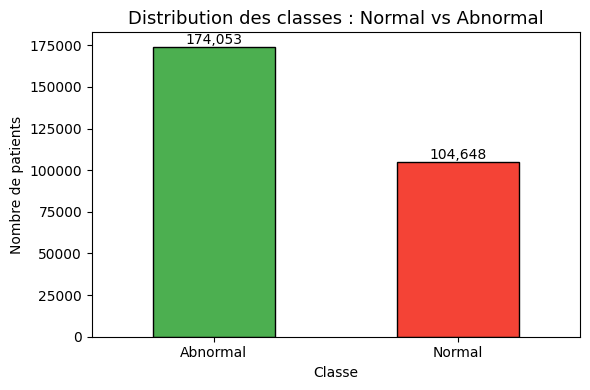

In [13]:
plt.figure(figsize=(6, 4))
ax = df['label'].value_counts().plot(kind='bar', color=['#4CAF50', '#F44336'], edgecolor='black')
ax.set_title("Distribution des classes : Normal vs Abnormal", fontsize=13)
ax.set_xlabel("Classe"); ax.set_ylabel("Nombre de patients")
ax.set_xticklabels(['Abnormal', 'Normal'], rotation=0)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig("distribution_target.png", dpi=150)
plt.show()

#### 3.2. Détection des outliers (méthode IQR)

on exclut les colonnes binaires (0/1) car la méthode IQR n'est pas applicable à des variables binaires (bornes = 0 implique que tous les "1" seraient classés comme outliers, ce qui est faux).

In [14]:
binary_cols = ['family_history', 'high_blood_pressure']
numeric_cols = [c for c in df.select_dtypes(include=[np.number]).columns
                if c not in binary_cols]

def count_outliers(df, col):
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    return n_out, lower, upper

outlier_summary = []
for col in numeric_cols:
    n_out, lo, hi = count_outliers(df, col)
    outlier_summary.append({
        'colonne'     : col,
        'outliers'    : n_out,
        '%'           : round((n_out / len(df)) * 100, 2),
        'borne_basse' : round(lo, 2),
        'borne_haute' : round(hi, 2)
    })

df_outliers = pd.DataFrame(outlier_summary)
print("\nRésumé des outliers (IQR) des colonnes continues uniquement")
print(df_outliers.to_string(index=False))


Résumé des outliers (IQR) des colonnes continues uniquement
           colonne  outliers     %  borne_basse  borne_haute
               age         0  0.00       -22.00       122.00
               bmi      1005  0.36         5.97        48.74
       HbA1c_level         0  0.00         3.17         9.08
           glucose      2028  0.73        10.00       250.00
       cholesterol         0  0.00       138.00       306.00
       sleep_hours      1526  0.55         3.94         9.95
     triglycerides         0  0.00       -42.62       412.38
    blood_pressure     30308 10.87       146.28       153.38
         crp_level     30295 10.87         6.60         8.45
homocysteine_level     30989 11.12        11.69        13.28
       systolic_bp     27371  9.82        96.50       172.50
      diastolic_bp     23230  8.34        63.50       115.50
    alcohol_intake     32706 11.74         2.75        27.15
       salt_intake     33549 12.04         3.30        13.70
        heart_rate     2

#### 3.3. Matrice de corrélation avec la target

In [15]:
# Création d'une version numérique temporaire de "label" pour l'analyse de corrélation.
df_corr = df.copy()
df_corr['label_num'] = df_corr['label'].map({'Normal': 0, 'Abnormal': 1})


Corrélations avec la target (label_num)
  HbA1c_level                  : +0.4527
  age                          : +0.2570
  bmi                          : +0.0705
  glucose                      : +0.0463
  sleep_hours                  : +0.0363
  cholesterol                  : +0.0213
  blood_pressure               : +0.0105
  systolic_bp                  : +0.0069
  homocysteine_level           : +0.0024
  salt_intake                  : +0.0010
  heart_rate                   : -0.0004
  diastolic_bp                 : -0.0011
  hdl                          : -0.0023
  alcohol_intake               : -0.0054
  ldl                          : -0.0098
  crp_level                    : -0.0350
  triglycerides                : -0.3570


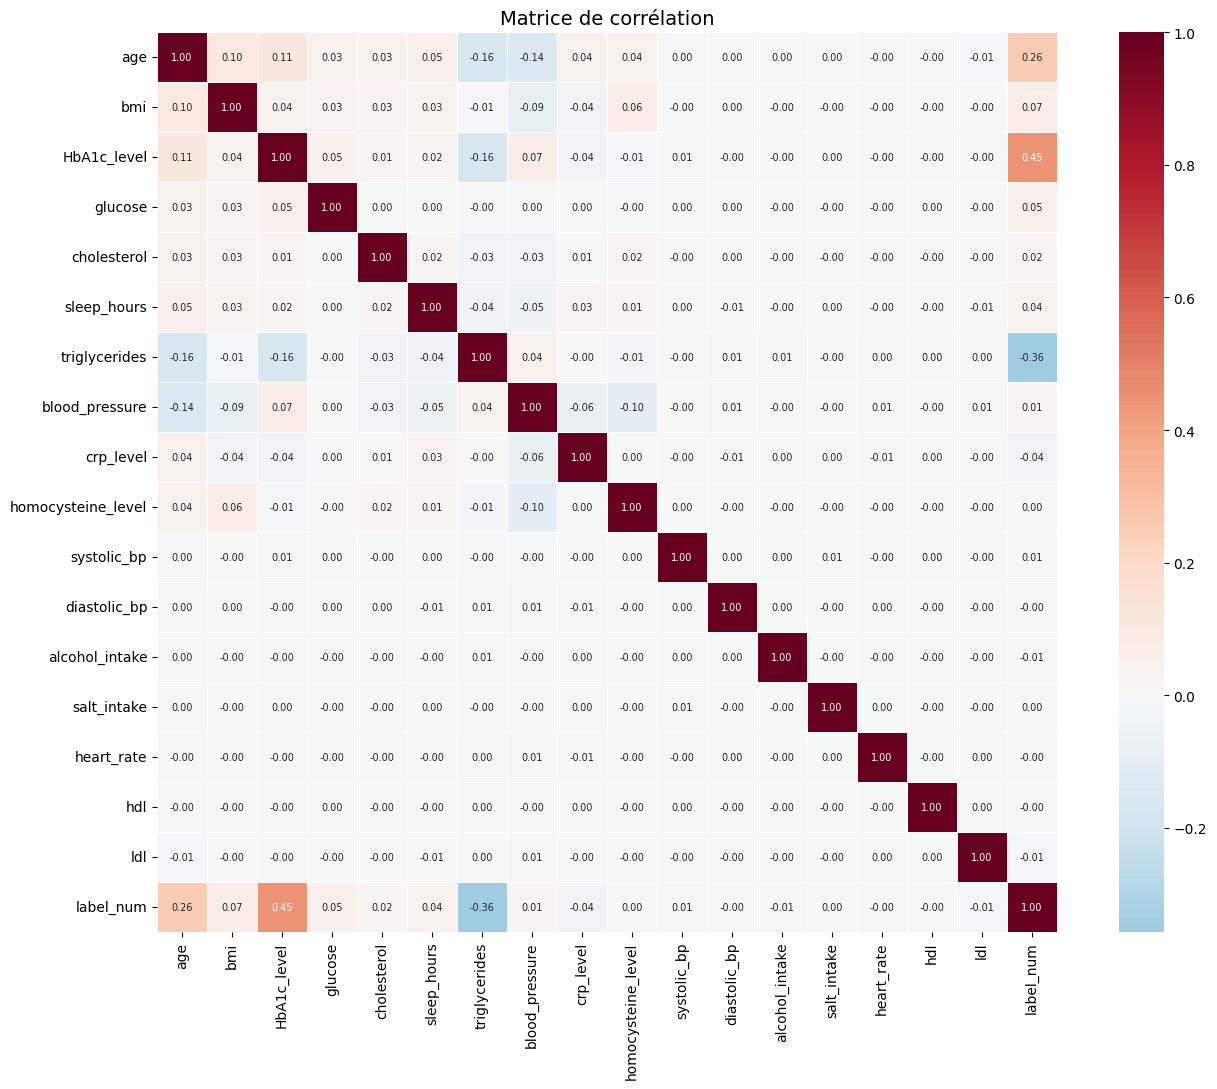

In [16]:
# On retire les colonnes textuelles pour ne garder que les numériques
df_corr_num = df_corr.select_dtypes(include=[np.number])

corr_matrix = df_corr_num.corr()
corr_with_label = (corr_matrix['label_num']
                   .drop('label_num')
                   .sort_values(ascending=False))

print("\nCorrélations avec la target (label_num)")
for feat, val in corr_with_label.items():
    print(f"  {feat:<28} : {val:+.4f}")

plt.figure(figsize=(14, 11))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.4,
            annot_kws={"size": 7})
plt.title("Matrice de corrélation", fontsize=14)
plt.tight_layout()
plt.savefig("matrice_correlation.png", dpi=150)
plt.show()

In [17]:
# Nettoyage : suppression de label_num 
del df_corr, df_corr_num

## 4. PRETRAITEMENT ET ENCODAGE

In [18]:
df_encoded = df.copy()

In [19]:
df_encoded.head()

,gender,smoking,age,bmi,HbA1c_level,glucose,cholesterol,sleep_hours,triglycerides,physical_activity,...,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,label
0,Female,Never,9,19.20,5.8,158.0,214.703704,6.864403,246.703704,High,...,135.380192,89.539936,14.777636,8.685304,74.329073,65.651757,129.220447,Primary,Retired,Normal
1,Female,Never,3,22.55,6.6,159.0,214.703704,6.864403,246.703704,High,...,135.380192,89.539936,14.777636,8.685304,74.329073,65.651757,129.220447,Primary,Retired,Normal
2,Female,Never,3,22.89,4.0,126.0,214.703704,6.864403,246.703704,High,...,135.380192,89.539936,14.777636,8.685304,74.329073,65.651757,129.220447,Primary,Retired,Normal
3,Female,Never,3,23.12,6.2,85.0,214.703704,6.864403,246.703704,High,...,135.380192,89.539936,14.777636,8.685304,74.329073,65.651757,129.220447,Primary,Retired,Normal
4,Female,Never,4,19.61,5.7,155.0,214.703704,6.864403,246.703704,High,...,135.380192,89.539936,14.777636,8.685304,74.329073,65.651757,129.220447,Primary,Retired,Normal


#### 4.1. Encodage des variables binaires 

In [20]:
binary_yesno = ['family_history', 'high_blood_pressure']
for col in binary_yesno:
    df_encoded[col] = df_encoded[col].map({'Yes': 1, 'No': 0})

#### 4.2. Encodage des variables ordinales (ordre logique métier)

In [21]:
ordinal_mappings = {
    'physical_activity' : {'Low': 0, 'Moderate': 1, 'High': 2},
    'stress_level'      : {'Low': 0, 'Medium': 1,   'High': 2},
    'sugar_consumption' : {'Low': 0, 'Medium': 1,   'High': 2},
}
for col, mapping in ordinal_mappings.items():
    df_encoded[col] = df_encoded[col].map(mapping)

#### 4.3. One-Hot Encoding

In [22]:
ohe_cols = ['gender', 'smoking', 'education_level', 'employment_status']
df_encoded = pd.get_dummies(df_encoded, columns=ohe_cols, drop_first=True)

#### 4.4. Encodage de la target

In [23]:
df_encoded['label'] = df_encoded['label'].map({'Normal': 0, 'Abnormal': 1})

In [24]:
# Conversion des booléens éventuels en int
bool_cols = df_encoded.select_dtypes(include='bool').columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

print("\nAperçu après encodage")
print(df_encoded.head())
print(f"\nShape : {df_encoded.shape}")
print(f"\nTypes :\n{df_encoded.dtypes}")


Aperçu après encodage
   age    bmi  HbA1c_level  glucose  cholesterol  sleep_hours  triglycerides  \
0    9  19.20          5.8    158.0   214.703704     6.864403     246.703704   
1    3  22.55          6.6    159.0   214.703704     6.864403     246.703704   
2    3  22.89          4.0    126.0   214.703704     6.864403     246.703704   
3    3  23.12          6.2     85.0   214.703704     6.864403     246.703704   
4    4  19.61          5.7    155.0   214.703704     6.864403     246.703704   

   physical_activity  family_history  stress_level  ...        hdl  \
0                  2               0             2  ...  65.651757   
1                  2               0             2  ...  65.651757   
2                  2               0             2  ...  65.651757   
3                  2               0             2  ...  65.651757   
4                  2               0             2  ...  65.651757   

          ldl  label  gender_Male  smoking_Former  smoking_Never  \
0  129.

## 5. SPLIT TRAIN / TEST

In [25]:
X = df_encoded.drop('label', axis=1)
y = df_encoded['label']

In [26]:
# Split stratifié (pour garantir un même ratio Normal/Abnormal dans train et test) 80/20 pour conserver la distribution des classes
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          
)

print("\nSplit train/test")
print(f"X_train : {X_train.shape}  |  X_test : {X_test.shape}")
print(f"Distribution train → Normal: {(y_train==0).sum()} | Abnormal: {(y_train==1).sum()}")
print(f"Distribution test  → Normal: {(y_test==0).sum()}  | Abnormal: {(y_test==1).sum()}")


Split train/test
X_train : (222960, 29)  |  X_test : (55741, 29)
Distribution train → Normal: 83718 | Abnormal: 139242
Distribution test  → Normal: 20930  | Abnormal: 34811


## 6. STANDARDISATION

Le scaler est fitté uniquement sur X_train, puis appliqué le (transform) sur X_train ET X_test. Car filtrer le scaler sur tout le dataset (avant split) est du data leakage.

In [27]:
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns

scaler = StandardScaler()
X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test[numeric_features]  = scaler.transform(X_test[numeric_features])

print("\nStandardisation appliquée")
print(f"Features standardisées : {len(numeric_features)}")


Standardisation appliquée
Features standardisées : 22


## 7. SÉLECTION DE FEATURES (SelectKBest)

SelectKBest est aussi filtré uniquement sur X_train, puis appliqué sur X_train et X_test (même logique que le scaler).

In [28]:
selector = SelectKBest(score_func=f_classif, k=20)
X_train_sel = selector.fit_transform(X_train, y_train)
X_test_sel  = selector.transform(X_test)

selected_features = X_train.columns[selector.get_support()].tolist()

scores_df = pd.DataFrame({
    'feature': X_train.columns,
    'score'  : selector.scores_
}).sort_values('score', ascending=False)

print("\nScores des features (f_classif)")
print(scores_df.to_string(index=False))

print(f"\n{len(selected_features)} features sélectionnées")
print(selected_features)


Scores des features (f_classif)
                     feature        score
                 HbA1c_level 57391.479468
               triglycerides 32360.962604
                         age 15615.835124
               smoking_Never 14918.337941
         high_blood_pressure  8309.238729
           physical_activity  5888.683136
              family_history  2963.243218
              smoking_Former  2308.831124
    education_level_Tertiary  2122.375265
           sugar_consumption  1147.946635
                         bmi  1089.248213
                 gender_Male   910.344343
                stress_level   481.721095
                     glucose   474.133335
                   crp_level   299.472924
   education_level_Secondary   291.934332
                 sleep_hours   266.549898
employment_status_Unemployed   135.367191
                 cholesterol    90.635081
   employment_status_Retired    54.574039
              blood_pressure    34.351874
                         ldl    19.412181
 

## 8. MODÉLISATION AVEC RANDOM FOREST + GRIDSEARCHCV

#### 8.1. Modèle de base (baseline)

In [29]:
print("\nRandom Forest - baseline")

rf_base = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',    # gestion du déséquilibre de classes
    random_state=42,
    n_jobs=-1
)
rf_base.fit(X_train_sel, y_train)

train_acc_base = rf_base.score(X_train_sel, y_train)
test_acc_base  = rf_base.score(X_test_sel,  y_test)
gap_base       = train_acc_base - test_acc_base

print(f"Train Accuracy : {train_acc_base:.4f}")
print(f"Test  Accuracy : {test_acc_base:.4f}")
print(f"Gap            : {gap_base:.4f}  "
      f"{'Overfitting probable !' if gap_base > 0.05 else 'OK'}")


Random Forest - baseline
Train Accuracy : 0.9982
Test  Accuracy : 0.8767
Gap            : 0.1215  Overfitting probable !


#### 8.2. GridSearchCV pour optimiser les hyperparamètres

In [30]:
# On cherche les meilleurs hyperparamètres qui réduisent l'overfitting tout en maximisant l'AUC-ROC en validation croisée.
print("\nGridSearchCV")
param_grid = {
    'n_estimators'    : [100],
    'max_depth'       : [10, 15, 20],
    'min_samples_split': [5, 10],
    'min_samples_leaf' : [2, 4],
    'class_weight'    : ['balanced']
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator  = RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid = param_grid,
    cv         = skf,
    scoring    = 'roc_auc',
    n_jobs     = -1,
    verbose    = 1,
    refit      = True
)

grid_search.fit(X_train_sel, y_train)
print(f"\nMeilleurs hyperparamètres : {grid_search.best_params_}")
print(f"Meilleur AUC-ROC (CV)     : {grid_search.best_score_:.4f}")
rf_best = grid_search.best_estimator_


GridSearchCV
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Meilleurs hyperparamètres : {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 100}
Meilleur AUC-ROC (CV)     : 0.9394


#### 8.3. Vérification overfitting après optimisation

In [31]:
train_acc_opt = rf_best.score(X_train_sel, y_train)
test_acc_opt  = rf_best.score(X_test_sel,  y_test)
gap_opt       = train_acc_opt - test_acc_opt

print(f"\nComparaison avant / après GridSearchCV")
print(f"{'Métrique':<20} {'Baseline':>12} {'Optimisé':>12}")
print(f"{'─'*46}")
print(f"{'Train Accuracy':<20} {train_acc_base:>12.4f} {train_acc_opt:>12.4f}")
print(f"{'Test  Accuracy':<20} {test_acc_base:>12.4f}  {test_acc_opt:>12.4f}")
print(f"{'Gap':<20} {gap_base:>12.4f} {gap_opt:>12.4f}  "
      f"{'Overfitting !' if gap_opt > 0.05 else 'OK'}")


Comparaison avant / après GridSearchCV
Métrique                 Baseline     Optimisé
──────────────────────────────────────────────
Train Accuracy             0.9982       0.8856
Test  Accuracy             0.8767        0.8820
Gap                        0.1215       0.0036  OK


#### 8.4. Cross-validation finale (sur X_train uniquement)

In [32]:
print("\nCross-Validation (5-Fold stratifiée)")

cv_scores = cross_val_score(
    rf_best, X_train_sel, y_train,
    cv=skf, scoring='roc_auc', n_jobs=-1
)

print(f"AUC-ROC moyen (CV) : {cv_scores.mean():.4f}  "
      f"(± {cv_scores.std():.4f})")


Cross-Validation (5-Fold stratifiée)
AUC-ROC moyen (CV) : 0.9394  (± 0.0008)


## 9. EVALUATION COMPLETE SUR LE JEU DE TEST

#### 9.1. Seuil optimal (Youden Index) calculé sur X_train

In [33]:
# Le seuil est déterminé à partir des prédictions sur X_train
y_proba_train = rf_best.predict_proba(X_train_sel)[:, 1]
fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_train, y_proba_train)
youden_idx = np.argmax(tpr_tr - fpr_tr)
threshold  = float(thresholds_tr[youden_idx])

print(f"\nSeuil optimal (Youden, calculé sur train) : {threshold:.3f}")


Seuil optimal (Youden, calculé sur train) : 0.603


#### 9.2. Prédictions sur le test 

In [34]:
y_proba = rf_best.predict_proba(X_test_sel)[:, 1]
y_pred  = (y_proba >= threshold).astype(int)

#### 9.3. Métriques

In [35]:
auc  = roc_auc_score(y_test, y_proba)
ap   = average_precision_score(y_test, y_proba)
mcc  = matthews_corrcoef(y_test, y_pred)
kap  = cohen_kappa_score(y_test, y_pred)
bri  = brier_score_loss(y_test, y_proba)

cm        = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

#### 9.4. Intervalles de confiance bootstrap (IC 95%) 

In [36]:
def bootstrap_ci(y_true, y_proba, metric_fn, n=1000, ci=0.95):
    scores, idx_all = [], np.arange(len(y_true))
    for _ in range(n):
        idx = resample(idx_all, replace=True)
        try:
            scores.append(metric_fn(np.array(y_true)[idx],
                                    np.array(y_proba)[idx]))
        except Exception:
            continue
    alpha = (1 - ci) / 2
    return np.mean(scores), np.percentile(scores, alpha*100), np.percentile(scores, (1-alpha)*100)

auc_mean, auc_lo, auc_hi = bootstrap_ci(y_test, y_proba, roc_auc_score)
mcc_fn = lambda yt, yp: matthews_corrcoef(yt, (yp >= threshold).astype(int))
mcc_mean, mcc_lo, mcc_hi = bootstrap_ci(y_test, y_proba, mcc_fn)

#### 9.5. Affichage

In [37]:
print(f"\n{'='*60}")
print(f"  RÉSULTATS FINAUX : Random Forest optimisé")
print(f"{'='*60}")
print(f"  AUC-ROC      : {auc:.4f}  [IC 95% : {auc_lo:.4f} – {auc_hi:.4f}]")
print(f"  AUC-PR       : {ap:.4f}")
print(f"  MCC          : {mcc:.4f}  [IC 95% : {mcc_lo:.4f} – {mcc_hi:.4f}]")
print(f"  Cohen Kappa  : {kap:.4f}")
print(f"  Brier Score  : {bri:.4f}")
print(f"  Sensibilité  : {sensitivity:.4f}")
print(f"  Spécificité  : {specificity:.4f}")
print(f"\n{classification_report(y_test, y_pred, target_names=['Normal', 'Abnormal'])}")


  RÉSULTATS FINAUX : Random Forest optimisé
  AUC-ROC      : 0.9397  [IC 95% : 0.9380 – 0.9415]
  AUC-PR       : 0.9631
  MCC          : 0.6772  [IC 95% : 0.6706 – 0.6830]
  Cohen Kappa  : 0.6767
  Brier Score  : 0.0913
  Sensibilité  : 0.8631
  Spécificité  : 0.8200

              precision    recall  f1-score   support

      Normal       0.78      0.82      0.80     20930
    Abnormal       0.89      0.86      0.88     34811

    accuracy                           0.85     55741
   macro avg       0.84      0.84      0.84     55741
weighted avg       0.85      0.85      0.85     55741



## 10. VISUALISATIONS

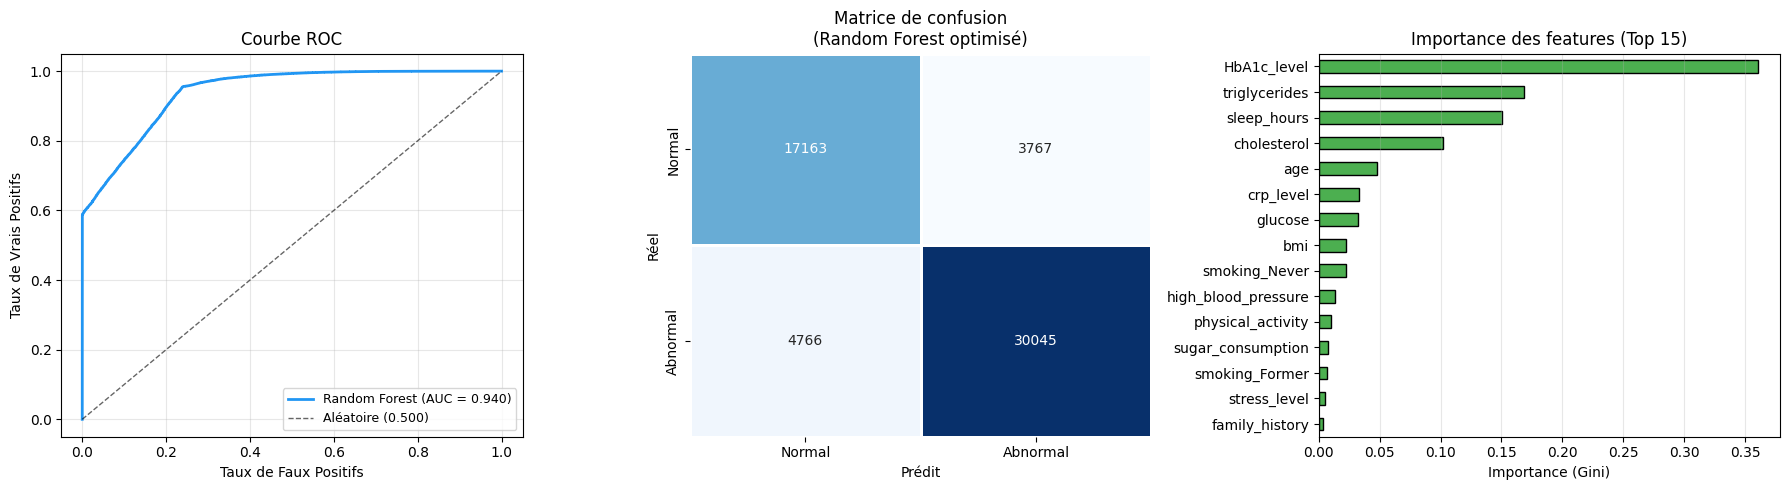

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Courbe ROC
ax = axes[0]
fpr, tpr, _ = roc_curve(y_test, y_proba)
ax.plot(fpr, tpr, lw=2, color='#2196F3',
        label=f'Random Forest (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.6, label='Aléatoire (0.500)')
ax.set_xlabel("Taux de Faux Positifs")
ax.set_ylabel("Taux de Vrais Positifs")
ax.set_title("Courbe ROC")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# Matrice de confusion
ax2 = axes[1]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Abnormal'],
            yticklabels=['Normal', 'Abnormal'],
            ax=ax2, cbar=False, linewidths=1)
ax2.set_xlabel("Prédit")
ax2.set_ylabel("Réel")
ax2.set_title("Matrice de confusion\n(Random Forest optimisé)")

# Importance des features (top 15)
ax3 = axes[2]
importances = pd.Series(
    rf_best.feature_importances_,
    index=selected_features
).sort_values(ascending=True).tail(15)
importances.plot(kind='barh', ax=ax3, color='#4CAF50', edgecolor='black')
ax3.set_title("Importance des features (Top 15)")
ax3.set_xlabel("Importance (Gini)")
ax3.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig("resultats_random_forest.png", dpi=150, bbox_inches='tight')
plt.show()

## 11. SAUVEGARDE DES DONNEES PRETRAITEES ET DU MODELE

In [43]:
import joblib
X_train_raw_df = pd.DataFrame(X_train_sel, columns=selected_features)
X_test_raw_df  = pd.DataFrame(X_test_sel,  columns=selected_features)

X_train_raw_df.to_csv("X_train.csv", index=False)
X_test_raw_df.to_csv("X_test.csv",   index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv",   index=False)

# Modèle optimisé
joblib.dump(rf_best, "random_forest_optimise.pkl")

print("\nSauvegarde terminée")
print("  X_train.csv, X_test.csv, y_train.csv, y_test.csv")
print("  random_forest_optimise.pkl")
print(f"\n  Features exportées ({len(selected_features)}) :")
for f in selected_features:
    print(f"    - {f}")


Sauvegarde terminée
  X_train.csv, X_test.csv, y_train.csv, y_test.csv
  random_forest_optimise.pkl

  Features exportées (20) :
    - age
    - bmi
    - HbA1c_level
    - glucose
    - cholesterol
    - sleep_hours
    - triglycerides
    - physical_activity
    - family_history
    - stress_level
    - high_blood_pressure
    - sugar_consumption
    - crp_level
    - gender_Male
    - smoking_Former
    - smoking_Never
    - education_level_Secondary
    - education_level_Tertiary
    - employment_status_Retired
    - employment_status_Unemployed
